# 📱 PhonePricer AI: End-to-End Smartphone Price Prediction Using Machine Learning
### Supervised Regression System for Fair-Market Valuation in Indian Rupees (INR)

---

## 📌 Project Overview
**PhonePricer AI** is a production-grade Machine Learning regression system engineered to predict smartphone retail prices based on microarchitecture, semiconductor lithography, display panel technology, memory bandwidth, optical sensors, and battery specifications.

### 🎯 Key Objectives:
1. **Regression Goal**: Predict the continuous market price `Price_INR` given hardware parameters $\mathbf{x} \in \mathbb{R}^d$.
2. **Hardware Domain Physics**: Respect physical constraints (e.g. non-negative marginal return for battery capacity holding all other components identical).
3. **Anti-Leakage Data Pipeline**: Strict isolation between Training (70%), Validation (15%), and Test (15%) partitions.
4. **Comprehensive Model Benchmarking**: Evaluate 16+ regression algorithms (Linear, Regularized, Robust, Tree Ensembles, Boosting, SVR, and Bounded Estimators).
5. **Model Explainability**: Identify primary cost drivers via Permutation Importance and Standardized Regression Coefficients.
6. **Inference API**: Production prediction engine with automated validation and realistic confidence bounds.

---
## 📦 Section 2: Import Required Libraries
Import all standard mathematical, tabular, visualization, and machine learning libraries required for the pipeline.

**What this cell does:** Import standard Python utilities and configure warning behavior.

In [1]:
import os
import sys
import re
import time
import json
import warnings
warnings.filterwarnings('ignore')

# Numerical & Data Processing


**What this cell does:** Import NumPy and Pandas for numerical operations and tabular data processing.

In [2]:
import numpy as np
import pandas as pd
try:
    from IPython.display import display
except ImportError:
    display = print




**What this cell does:** Import plotting libraries and set the default chart appearance.

In [3]:
# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

# Optimization & Custom Estimators


**What this cell does:** Import optimization tools and base estimator utilities for the custom regression models.

In [4]:
from scipy.optimize import lsq_linear
from sklearn.base import BaseEstimator, RegressorMixin, clone

# Scikit-Learn Preprocessing & Pipelines


**What this cell does:** Import scikit-learn preprocessing, pipeline, model-selection, and feature-inspection utilities.

In [5]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import KFold, cross_val_score, GridSearchCV
from sklearn.inspection import permutation_importance

# Baseline & Regression Models


**What this cell does:** Import baseline and regression algorithms used for model comparison.

In [6]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, HuberRegressor, BayesianRidge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor,
    VotingRegressor,
    StackingRegressor
)
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor

# Advanced Gradient Boosting


**What this cell does:** Import advanced gradient-boosting libraries.

In [7]:
import xgboost as xgb
import lightgbm as lgb

try:
    from catboost import CatBoostRegressor
except ImportError:
    import subprocess
    import sys
    print("CatBoost not found. Installing catboost library...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "catboost"])
    from catboost import CatBoostRegressor

# Model Persistence & Evaluation Metrics

**What this cell does:** Import model-saving utilities and regression evaluation metrics.

In [8]:
import joblib
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, median_absolute_error

print("✅ All core libraries successfully imported.")
print(f"NumPy: {np.__version__} | Pandas: {pd.__version__} | Scikit-Learn: {joblib.__version__}")

✅ All core libraries successfully imported.
NumPy: 2.4.6 | Pandas: 2.2.3 | Scikit-Learn: 1.6.0


---
## ⚙️ Section 3: Google Colab Environment Setup
Detect runtime environment, check Python version, and install any missing dependencies cleanly.

**What this cell does:** Detect whether the notebook is running in Google Colab or a local Jupyter environment, install the required boosting packages in Colab, and print the Python environment details.

In [9]:
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    print("🚀 Running inside Google Colab environment.")
    # Install additional boosting libraries if needed
    !pip install -q xgboost lightgbm catboost joblib
else:
    print("💻 Running inside local or standard Jupyter environment.")

print(f"Python Executable: {sys.executable}")
print(f"Python Version: {sys.version.split()[0]}")

🚀 Running inside Google Colab environment.
Python Executable: /usr/bin/python3
Python Version: 3.13.18


---
## 📂 Section 4: Dataset Upload
Upload the authentic smartphone dataset (`Coa-12.csv`). If running in Colab, the interactive file uploader will prompt you to select the CSV from your computer.

**What this cell does:** Set the expected dataset filename and initialize the dataset path. These values are used by the following file-location checks.

In [10]:
DATASET_FILENAME = "Coa-12.csv"
DATASET_PATH ='/content/Coa-12.csv'

# Check common relative local paths first


**What this cell does:** Create a list of likely dataset locations and search those locations. If a file is found, store its path in `DATASET_PATH`.

In [11]:
candidate_paths = [
    DATASET_FILENAME,
    f"data/raw/{DATASET_FILENAME}",
    f"../{DATASET_FILENAME}",
    f"../data/raw/{DATASET_FILENAME}",
    "coa-12.xlsx",
    "../coa-12.xlsx"
]

for p in candidate_paths:
    if os.path.exists(p):
        DATASET_PATH = p
        print(f"✅ Found existing local dataset at: {DATASET_PATH}")
        break

# If in Colab and file is not yet uploaded, trigger interactive file uploader


✅ Found existing local dataset at: Coa-12.csv


**What this cell does:** If the dataset was not found locally and the notebook is in Colab, ask the user to upload it. Raise an error if no supported dataset file is available.

In [12]:
if DATASET_PATH is None and IN_COLAB:
    from google.colab import files
    print("📤 Please upload 'Coa-12.csv' using the file picker below:")
    uploaded = files.upload()
    for filename in uploaded.keys():
        if filename.endswith(".csv") or filename.endswith(".xlsx"):
            DATASET_PATH = filename
            print(f"✅ Uploaded dataset ready: {DATASET_PATH}")
            break

if DATASET_PATH is None:
    raise FileNotFoundError("Dataset file not found. Please upload 'Coa-12.csv' to proceed.")

---
## 🔍 Section 5: Dataset Loading & Initial Schema Inspection
Load the raw smartphone specifications into a Pandas DataFrame and inspect dimensions, columns, and sample records.

**What this cell does:** Read the selected CSV dataset into `raw_df`, then display its dimensions, column names, and first five records.

In [13]:
raw_df = pd.read_csv(DATASET_PATH)

print(f"Dataset Shape: {raw_df.shape[0]} smartphone records, {raw_df.shape[1]} raw attributes.")
print(f"\nColumns ({len(raw_df.columns)}):\n{list(raw_df.columns)}")
display(raw_df.head(5))

Dataset Shape: 91 smartphone records, 30 raw attributes.

Columns (30):
['Phone_Company', 'Phone_Model', 'SoC', 'Processor_Core_Count', 'Processor_Core1', 'Processor_Core1_Count', 'Processor_Core1_Frequency_GHz', 'Processor_Core2', 'Processor_Core2_Count', 'Processor_Core2_Frequency_GHz', 'Processor_Core3', 'Processor_Core3_Count', 'Processor_Core3_Frequency_GHz', 'RAM_Type', 'RAM_Size_GB', 'Cache_Memory_Core1', 'Cache_Memory_Core2', 'Cache_Memory_Core3', 'Storage_GB', 'Battery_Capacity_mAh', 'ISA', 'Frequency_of_Different_Cores', 'Process_Technology_nm', 'Display_Type', 'Display_Resolution', 'Display_Resolution_Width_px', 'Display_Resolution_Height_px', 'Refresh_Rate_Hz', 'Camera_Specifications', 'Price_INR']


,Phone_Company,Phone_Model,SoC,Processor_Core_Count,Processor_Core1,Processor_Core1_Count,Processor_Core1_Frequency_GHz,Processor_Core2,Processor_Core2_Count,Processor_Core2_Frequency_GHz,...,ISA,Frequency_of_Different_Cores,Process_Technology_nm,Display_Type,Display_Resolution,Display_Resolution_Width_px,Display_Resolution_Height_px,Refresh_Rate_Hz,Camera_Specifications,Price_INR
0,Xiaomi Redmi,Xiaomi Redmi 13 5G,Qualcomm SM4450 Snapdragon 4 Gen 2 AE (4 nm),8,Cortex-A78,2,2.3,Cortex-A55,6,1.95,...,Armv8.2-A,2x2.3 GHz Cortex-A78; 6x1.95 GHz Cortex-A55,4,"IPS LCD, 90Hz, 550 nits (HBM)",1080 x 2460 pixels (~396 ppi density),1080,2460,90,"Rear: 108 MP, f/1.8, (wide), 0.64µm, PDAF2 MP,...",18875
1,Xiaomi Redmi,Xiaomi Redmi 14R,Qualcomm SM4450 Snapdragon 4 Gen 2 (4 nm),8,Cortex-A78,2,2.2,Cortex-A55,6,1.95,...,Armv8.2-A,2x2.2 GHz Cortex-A78; 6x1.95 GHz Cortex-A55,4,"IPS LCD, 120Hz, 450 nits (typ), 600 nits (HBM)",720 x 1640 pixels (~260 ppi density),720,1640,120,"Rear: 13 MP, (wide), AF2 MPAuxiliary lens | Re...",15100
2,Xiaomi Redmi,Xiaomi Redmi 15C,Mediatek Dimensity 6300 (6 nm),8,Cortex-A76,2,2.4,Cortex-A55,6,2.00,...,Armv8.2-A,2x2.4 GHz Cortex-A76; 6x2 GHz Cortex-A55,6,"IPS LCD, 120Hz, 810 nits (HBM)","720 x 1600 pixels, 20:9 ratio (~254 ppi density)",720,1600,120,"Rear: 50 MP, f/1.8, 28mm (wide), 1/2.76"", 0.64...",15478
3,Xiaomi Redmi,Xiaomi Redmi A5 4G,Unisoc T7250 (12 nm),8,Cortex-A75,2,1.8,Cortex-A55,6,1.60,...,Armv8.2-A,2x1.8 GHz Cortex-A75; 6x1.6 GHz Cortex-A55,12,"IPS LCD, 120Hz, 1500 nits (HBM)",720 x 1640 pixels (~260 ppi density),720,1640,120,"Rear: 32 MP, f/1.8, (wide)Auxiliary lens | Rea...",8304
4,Xiaomi Redmi,Xiaomi Redmi K100 Pro,Qualcomm SM8850-AC Snapdragon 8 Elite Gen 5 (3...,8,Oryon V3 Phoenix L,2,4.6,Oryon V3 Phoenix M,6,3.62,...,Armv9.2-A,2x4.6 GHz Oryon V3 Phoenix L; 6x3.62 GHz Oryon...,3,"AMOLED, 68B colors, 185Hz, Dolby Vision, HDR V...","1156 x 2510 pixels, 19.5:9 ratio (~419 ppi den...",1156,2510,185,"Rear: 200 MP, f/1.7, 24mm (wide), 0.5µm, PDAF,...",52851


---
## 🔎 Section 6: Dataset Inspection & Quality Audit
Perform a systematic audit: detect missing values, check for duplicate rows and phone models, and summarize numerical features.

**What this cell does:** Inspect the raw dataset quality, including row count, missing values, duplicates, target-price statistics, and hardware summary statistics.

In [14]:
print("=== DATA QUALITY AUDIT ===")
print(f"Total Rows: {len(raw_df)}")
print(f"Total Missing Values: {raw_df.isnull().sum().sum()}")
print(f"Exact Duplicate Rows: {raw_df.duplicated().sum()}")
if 'Phone_Model' in raw_df.columns:
    print(f"Duplicate Phone Models: {raw_df['Phone_Model'].duplicated().sum()}")

print("\n=== TARGET PRICE (INR) DISTRIBUTION ===")
print(raw_df['Price_INR'].describe().round(2))

print("\n=== HARDWARE SUMMARY STATISTICS ===")
key_hw = [c for c in ['RAM_Size_GB', 'Storage_GB', 'Battery_Capacity_mAh', 'Process_Technology_nm', 'Refresh_Rate_Hz'] if c in raw_df.columns]
display(raw_df[key_hw].describe().round(2))

=== DATA QUALITY AUDIT ===
Total Rows: 91
Total Missing Values: 0
Exact Duplicate Rows: 0
Duplicate Phone Models: 0

=== TARGET PRICE (INR) DISTRIBUTION ===
count       91.00
mean     26784.54
std      15222.44
min       7550.00
25%      15289.00
50%      22651.00
75%      34164.50
max      75494.00
Name: Price_INR, dtype: float64

=== HARDWARE SUMMARY STATISTICS ===


,RAM_Size_GB,Storage_GB,Battery_Capacity_mAh,Process_Technology_nm,Refresh_Rate_Hz
count,91.00,91.00,91.00,91.00,91.00
mean,7.13,154.55,5585.16,6.55,115.44
std,2.98,83.76,1019.99,5.38,23.77
min,2.00,16.00,2990.00,3.00,60.00
25%,4.00,128.00,5000.00,4.00,120.00
50%,8.00,128.00,5200.00,4.00,120.00
75%,8.00,256.00,6050.00,6.00,120.00
max,16.00,512.00,8580.00,28.00,185.00


---
## 🧹 Section 7: Dedicated Data Cleaning
Apply verified cleaning rules:
- Distinguish legitimate structural zeros (Cluster 3 = 0 for dual-cluster octa-cores) from missing data.
- Validate core count physics ($C_1 + C_2 + C_3 = 8$).
- Ensure RAM and Storage capacities are strictly positive.
- Validate non-negative display resolutions and positive retail prices.

**What this cell does:** Define and run the dataset-cleaning function. It removes duplicates, handles structural zeros, converts numeric columns, and filters invalid records before creating `clean_df`.

In [15]:
def clean_smartphone_dataset(df_in: pd.DataFrame) -> pd.DataFrame:
    df = df_in.copy()

    # 1. Deduplication
    df = df.drop_duplicates().reset_index(drop=True)
    if 'Phone_Model' in df.columns:
        df = df.drop_duplicates(subset=['Phone_Model']).reset_index(drop=True)

    # 2. Handle Structural Zeros for Cluster 3
    if 'Processor_Core3_Count' in df.columns:
        df['Processor_Core3_Count'] = df['Processor_Core3_Count'].fillna(0).astype(int)
    if 'Processor_Core3_Frequency_GHz' in df.columns:
        df['Processor_Core3_Frequency_GHz'] = df['Processor_Core3_Frequency_GHz'].fillna(0.0).astype(float)
    if 'Cache_Memory_Core3' in df.columns:
        df['Cache_Memory_Core3'] = df['Cache_Memory_Core3'].fillna(0).astype(int)

    # 3. Numeric Conversions & Validations
    num_cols_to_coerce = [
        'RAM_Size_GB', 'Storage_GB', 'Battery_Capacity_mAh', 'Process_Technology_nm',
        'Display_Resolution_Width_px', 'Display_Resolution_Height_px', 'Refresh_Rate_Hz',
        'Processor_Core1_Count', 'Processor_Core1_Frequency_GHz',
        'Processor_Core2_Count', 'Processor_Core2_Frequency_GHz',
        'Cache_Memory_Core1', 'Cache_Memory_Core2', 'Price_INR'
    ]
    for col in num_cols_to_coerce:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors='coerce')

    # Remove records with missing price or invalid values
    df = df.dropna(subset=['Price_INR']).reset_index(drop=True)
    df = df[df['Price_INR'] > 0].reset_index(drop=True)
    df = df[df['RAM_Size_GB'] > 0].reset_index(drop=True)
    df = df[df['Storage_GB'] > 0].reset_index(drop=True)

    # Validate Core Sum physics
    core_sum = df['Processor_Core1_Count'] + df['Processor_Core2_Count'] + df['Processor_Core3_Count']
    valid_cores = (core_sum == 8)
    if not valid_cores.all():
        print(f"⚠️ Warning: Found {(~valid_cores).sum()} records with core counts != 8. Preserving valid hardware bounds.")

    return df

clean_df = clean_smartphone_dataset(raw_df)
print(f"✅ Cleaned Dataset: {clean_df.shape[0]} valid smartphone records preserved (100% data integrity).")

✅ Cleaned Dataset: 91 valid smartphone records preserved (100% data integrity).


---
## 📊 Section 8: Exploratory Data Analysis (EDA)
Visualize market price distribution and explore relationships between price and primary hardware specifications (RAM, Storage, Battery Capacity, CPU Frequencies, and Lithography).

**What this cell does:** Create a 3-by-3 plotting layout that will hold all nine exploratory charts.

In [75]:
plt.ioff()  # Prevent Jupyter from displaying the figure before all plots are added.
fig, axes = plt.subplots(3, 3, figsize=(18, 14))

# 1. Price Distribution


**What this cell does:** Plot the distribution of smartphone selling prices in Indian rupees.

In [76]:
sns.histplot(clean_df['Price_INR'], kde=True, ax=axes[0, 0], color='#0284c7')
axes[0, 0].set_title("1. Target Price Distribution (INR)", fontweight='bold')
axes[0, 0].set_xlabel("Price (INR)")

# 2. Brand vs Median Price


Text(0.5, 0, 'Price (INR)')

**What this cell does:** Compare median smartphone prices across phone brands.

In [77]:
brand_order = clean_df.groupby('Phone_Company')['Price_INR'].median().sort_values(ascending=False).index
sns.barplot(data=clean_df, x='Phone_Company', y='Price_INR', order=brand_order, ax=axes[0, 1], palette='Blues_r', estimator=np.median, ci=None)
axes[0, 1].set_title("2. Median Smartphone Price by Brand", fontweight='bold')
axes[0, 1].tick_params(axis='x', rotation=45)

# 3. RAM vs Price


**What this cell does:** Compare smartphone prices across RAM capacities.

In [78]:
sns.boxplot(data=clean_df, x='RAM_Size_GB', y='Price_INR', ax=axes[0, 2], palette='Blues')
axes[0, 2].set_title("3. Price by RAM Capacity (GB)", fontweight='bold')

# 4. Storage vs Price



Text(0.5, 1.0, '3. Price by RAM Capacity (GB)')

**What this cell does:** Compare smartphone prices across storage capacities.

In [79]:
sns.boxplot(data=clean_df, x='Storage_GB', y='Price_INR', ax=axes[1, 0], palette='Blues')
axes[1, 0].set_title("4. Price by Flash Storage (GB)", fontweight='bold')

# 5. Battery Capacity vs Price



Text(0.5, 1.0, '4. Price by Flash Storage (GB)')

**What this cell does:** Explore the relationship between battery capacity and smartphone price, including a trend line.

In [80]:
sns.scatterplot(data=clean_df, x='Battery_Capacity_mAh', y='Price_INR', hue='Phone_Company', ax=axes[1, 1], s=80, alpha=0.8, legend=False)
sns.regplot(data=clean_df, x='Battery_Capacity_mAh', y='Price_INR', ax=axes[1, 1], scatter=False, color='#e11d48')
axes[1, 1].set_title("5. Battery Capacity (mAh) vs Price", fontweight='bold')

# 6. Core 1 Clock Frequency vs Price



Text(0.5, 1.0, '5. Battery Capacity (mAh) vs Price')

**What this cell does:** Explore the relationship between the main CPU core frequency and smartphone price.

In [81]:
sns.scatterplot(data=clean_df, x='Processor_Core1_Frequency_GHz', y='Price_INR', ax=axes[1, 2], color='#0284c7', s=80)
sns.regplot(data=clean_df, x='Processor_Core1_Frequency_GHz', y='Price_INR', ax=axes[1, 2], scatter=False, color='#2563eb')
axes[1, 2].set_title("6. Prime Core Clock (GHz) vs Price", fontweight='bold')

# 7. Process Technology (nm) vs Price


Text(0.5, 1.0, '6. Prime Core Clock (GHz) vs Price')

**What this cell does:** Compare smartphone prices across semiconductor process technology values.

In [82]:
sns.boxplot(data=clean_df, x='Process_Technology_nm', y='Price_INR', ax=axes[2, 0], palette='Blues_r')
axes[2, 0].set_title("7. Lithography Node (nm) vs Price", fontweight='bold')

# 8. Refresh Rate vs Price


Text(0.5, 1.0, '7. Lithography Node (nm) vs Price')

**What this cell does:** Compare smartphone prices across display refresh rates.

In [83]:
sns.boxplot(data=clean_df, x='Refresh_Rate_Hz', y='Price_INR', ax=axes[2, 1], palette='Blues')
axes[2, 1].set_title("8. Display Refresh Rate (Hz) vs Price", fontweight='bold')

# 9. Correlation Heatmap


Text(0.5, 1.0, '8. Display Refresh Rate (Hz) vs Price')

**What this cell does:** Calculate hardware-feature correlations and display them as a heatmap, then finish and show the complete figure.

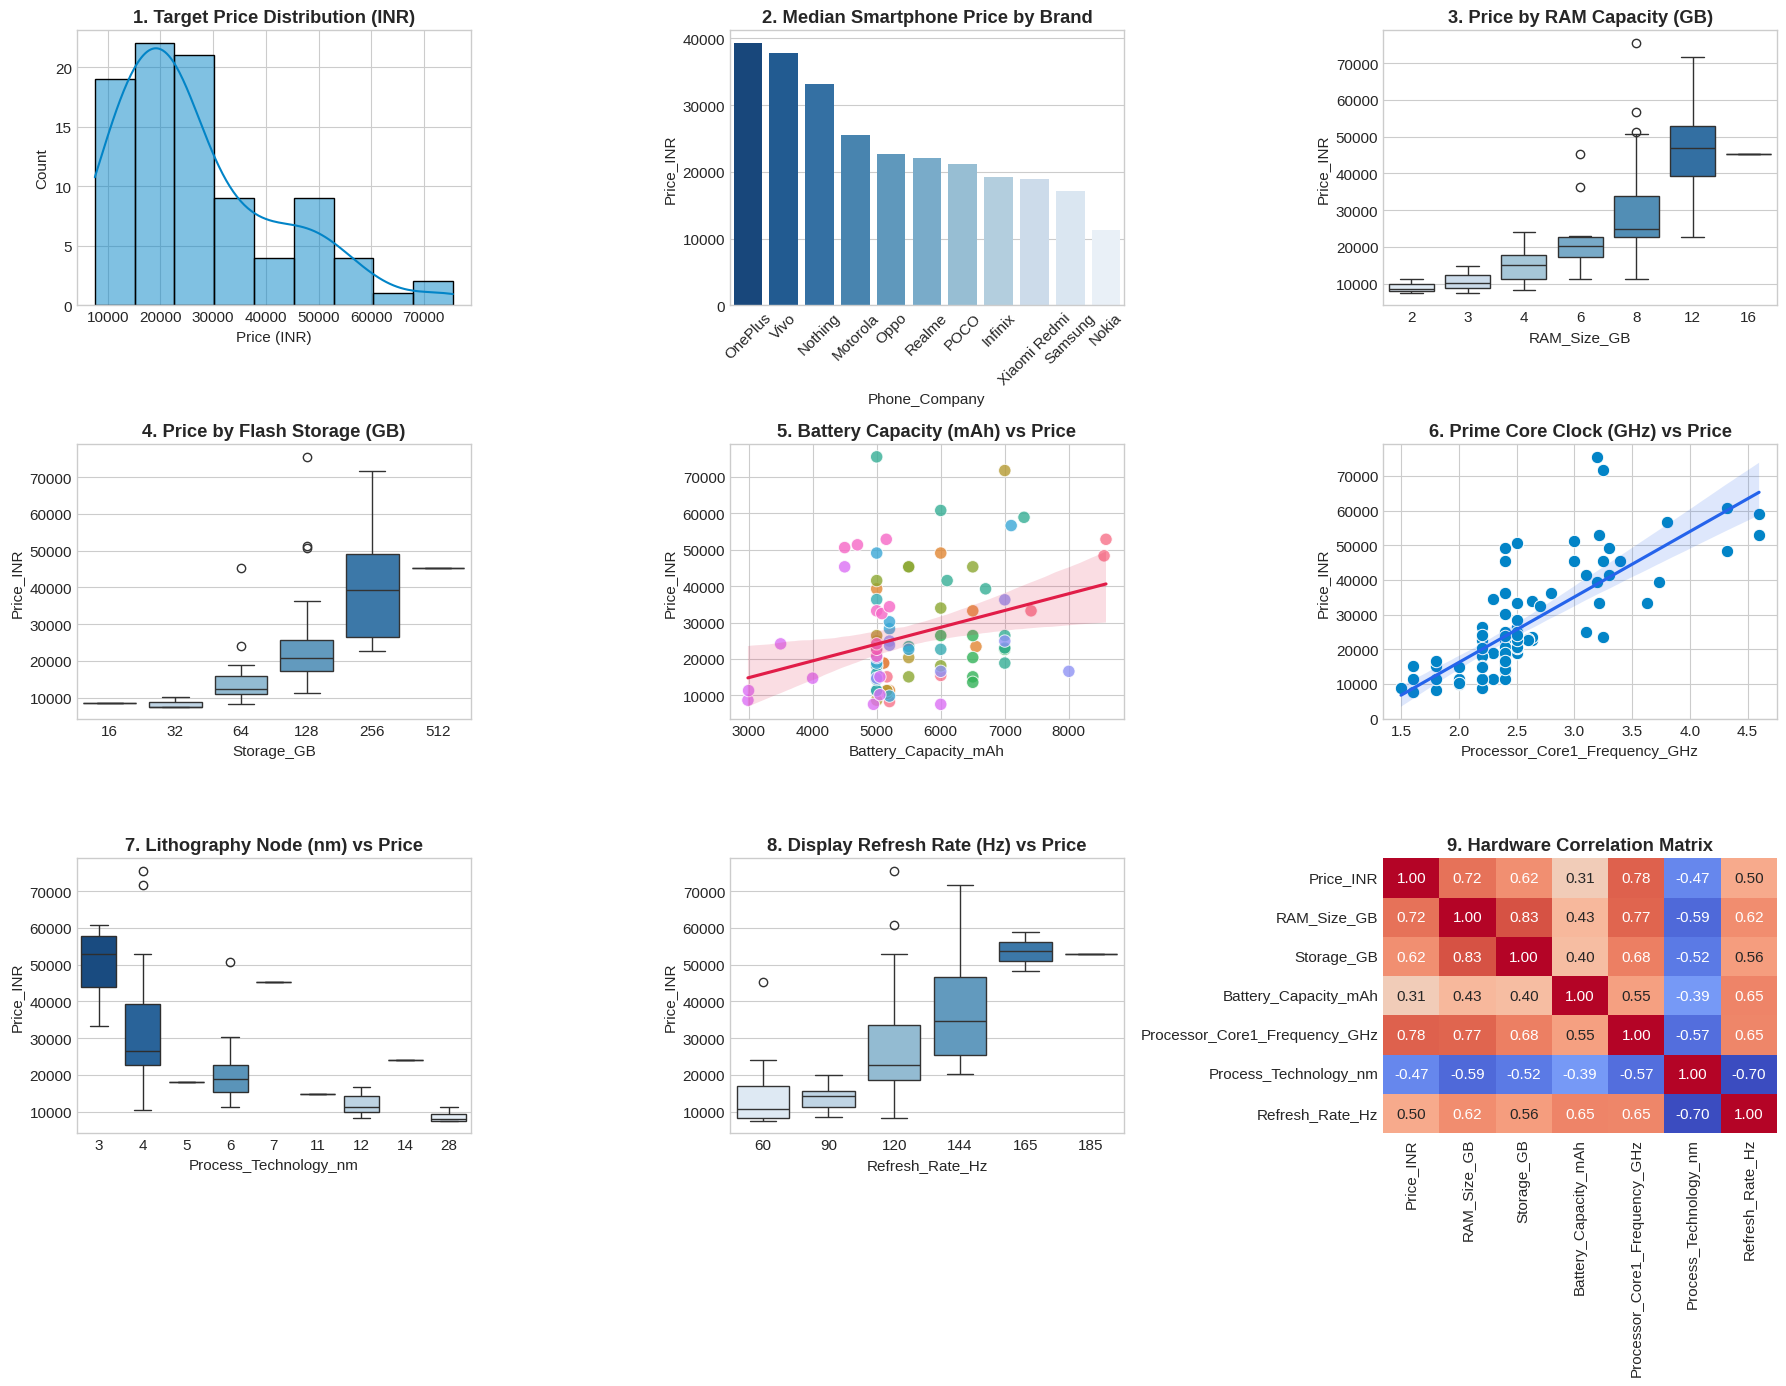

In [84]:
corr_cols = [c for c in ['Price_INR', 'RAM_Size_GB', 'Storage_GB', 'Battery_Capacity_mAh', 'Processor_Core1_Frequency_GHz', 'Process_Technology_nm', 'Refresh_Rate_Hz'] if c in clean_df.columns]
corr_matrix = clean_df[corr_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', ax=axes[2, 2], cbar=False)
axes[2, 2].set_title("9. Hardware Correlation Matrix", fontweight='bold')

plt.tight_layout()
plt.show()

---
## 🛠️ Section 9: Domain-Driven Feature Engineering
Synthesize microarchitecture and semiconductor metrics:
- **`Max_Core_Frequency_GHz`**: Single-core burst throughput.
- **`Weighted_Average_Frequency_GHz`**: Full compute capacity across all 8 cores.
- **`Silicon_Density`**: Frequency per nanometer ($	ext{GHz} / 	ext{nm}$).
- **`Total_Display_Pixels` & `Display_Bandwidth_MP_s`**: Display throughput.
- **`Memory_Score` & `Compute_Capability_Score`**: System capability indexes.
- **Categorical Encodings**: `SoC_Tier`, `SoC_Maker`, and `Display_Tech_Category`.

**What this cell does:** Define and run feature engineering. This derives additional CPU, display, memory, and hardware capability features used by the regression models.

In [85]:
def engineer_smartphone_features(df_in: pd.DataFrame) -> pd.DataFrame:
    df = df_in.copy()

    # 1. CPU Clusters Count
    c3_cnt = df['Processor_Core3_Count'].fillna(0) if 'Processor_Core3_Count' in df.columns else 0
    df['Num_CPU_Clusters'] = np.where(c3_cnt > 0, 3, 2)

    # 2. Maximum Single-Core Frequency
    c1_f = df['Processor_Core1_Frequency_GHz'].fillna(0.0)
    c2_f = df['Processor_Core2_Frequency_GHz'].fillna(0.0)
    c3_f = df['Processor_Core3_Frequency_GHz'].fillna(0.0) if 'Processor_Core3_Frequency_GHz' in df.columns else 0.0
    df['Max_Core_Frequency_GHz'] = np.maximum.reduce([c1_f, c2_f, c3_f])

    # 3. Weighted Average Core Frequency
    c1_c = df['Processor_Core1_Count'].fillna(1)
    c2_c = df['Processor_Core2_Count'].fillna(1)
    c3_c = df['Processor_Core3_Count'].fillna(0) if 'Processor_Core3_Count' in df.columns else 0
    tot_cores = np.maximum(c1_c + c2_c + c3_c, 1)
    df['Weighted_Average_Frequency_GHz'] = ((c1_c * c1_f) + (c2_c * c2_f) + (c3_c * c3_f)) / tot_cores

    # 4. Display Metrics
    w = df['Display_Resolution_Width_px'].fillna(1080)
    h = df['Display_Resolution_Height_px'].fillna(2400)
    hz = df['Refresh_Rate_Hz'].fillna(60)
    df['Total_Display_Pixels'] = w * h
    df['Display_Bandwidth_MP_s'] = (df['Total_Display_Pixels'] * hz) / 1e6

    # 5. Silicon Density
    nm = np.maximum(df['Process_Technology_nm'].fillna(4), 1)
    df['Silicon_Density'] = df['Max_Core_Frequency_GHz'] / nm

    # 6. Total Processor Cache
    ca1 = df['Cache_Memory_Core1'].fillna(0) if 'Cache_Memory_Core1' in df.columns else 0
    ca2 = df['Cache_Memory_Core2'].fillna(0) if 'Cache_Memory_Core2' in df.columns else 0
    ca3 = df['Cache_Memory_Core3'].fillna(0) if 'Cache_Memory_Core3' in df.columns else 0
    df['Total_Cache_KB'] = ca1 + ca2 + ca3

    # 7. Composite Capability Scores
    ram = df['RAM_Size_GB'].fillna(4)
    storage = df['Storage_GB'].fillna(64)
    df['Memory_Score'] = ram * storage
    df['Compute_Capability_Score'] = (ram * df['Max_Core_Frequency_GHz']) / nm

    # 8. Rear Camera MP Extraction
    def parse_camera_mp(cam_str):
        if not isinstance(cam_str, str): return 50.0
        m = re.search(r'(\d+(?:\.\d+)?)\s*MP', cam_str, re.IGNORECASE)
        return float(m.group(1)) if m else 50.0
    if 'Camera_Specifications' in df.columns:
        df['Rear_Camera_MP'] = df['Camera_Specifications'].apply(parse_camera_mp)
    else:
        df['Rear_Camera_MP'] = 50.0

    # 9. Categorical Abstractions
    # Display Tech
    if 'Display_Type' in df.columns:
        df['Display_Tech_Category'] = df['Display_Type'].apply(lambda s: 'AMOLED' if any(x in str(s).upper() for x in ['AMOLED', 'OLED']) else 'LCD')
    else:
        df['Display_Tech_Category'] = 'AMOLED'

    # SoC Maker & Tier
    def get_soc_maker(s):
        s_up = str(s).upper()
        if 'SNAPDRAGON' in s_up or 'QUALCOMM' in s_up: return 'Qualcomm'
        if 'DIMENSITY' in s_up or 'HELIO' in s_up or 'MEDIATEK' in s_up: return 'MediaTek'
        if 'EXYNOS' in s_up: return 'Exynos'
        if 'UNISOC' in s_up: return 'Unisoc'
        return 'Other'

    def get_soc_tier(row):
        s_up = str(row.get('SoC', '')).upper()
        nm_val = row.get('Process_Technology_nm', 6)
        freq_val = row.get('Max_Core_Frequency_GHz', 2.0)
        if any(x in s_up for x in ['8 GEN', '8 ELITE', '9300', '9400', 'A17', 'A18']) or (nm_val <= 4 and freq_val >= 3.2):
            return 'Flagship'
        if any(x in s_up for x in ['7 GEN', '7+ GEN', '8200', '8300', '8400']) or (nm_val <= 4 and freq_val >= 2.8):
            return 'Premium_Mid'
        if any(x in s_up for x in ['6 GEN', '7200', '7300', '6080', 'G99', 'G100']) or (nm_val <= 6):
            return 'Mid'
        return 'Budget'

    df['SoC_Maker'] = df['SoC'].apply(get_soc_maker) if 'SoC' in df.columns else 'Other'
    df['SoC_Tier'] = df.apply(get_soc_tier, axis=1)

    return df

eng_df = engineer_smartphone_features(clean_df)
print(f"✅ Feature Engineering Complete. Total Columns: {eng_df.shape[1]} (Added 14 derived hardware attributes).")

✅ Feature Engineering Complete. Total Columns: 43 (Added 14 derived hardware attributes).


---
## 🎯 Section 10: Define Input Features and Target Variable
Define the exact production feature matrix `X` and continuous target `y` (`Price_INR`).
- **21 Numerical Features** (including `Battery_Capacity_mAh`)
- **6 Categorical Features**

**What this cell does:** Choose the numerical and categorical input columns, identify `Price_INR` as the target, and construct the feature matrix `X` and target series `y`.

In [91]:
SELECTED_NUMERICAL_FEATURES = [
    "RAM_Size_GB",
    "Storage_GB",
    "Battery_Capacity_mAh",
    "Process_Technology_nm",
    "Display_Resolution_Width_px",
    "Display_Resolution_Height_px",
    "Refresh_Rate_Hz",
    "Processor_Core1_Frequency_GHz",
    "Processor_Core2_Frequency_GHz",
    "Processor_Core3_Count",
    "Processor_Core3_Frequency_GHz",
    "Cache_Memory_Core3",
    "Max_Core_Frequency_GHz",
    "Weighted_Average_Frequency_GHz",
    "Total_Display_Pixels",
    "Display_Bandwidth_MP_s",
    "Silicon_Density",
    "Total_Cache_KB",
    "Num_CPU_Clusters",
    "Memory_Score",
    "Compute_Capability_Score"
]

SELECTED_CATEGORICAL_FEATURES = [
    "Phone_Company",
    "RAM_Type",
    "ISA",
    "Display_Tech_Category",
    "SoC_Tier",
    "SoC_Maker"
]

TARGET_COLUMN = "Price_INR"

X = eng_df[SELECTED_NUMERICAL_FEATURES + SELECTED_CATEGORICAL_FEATURES].copy()
y = eng_df[TARGET_COLUMN].copy()

print(f"Feature Matrix X Shape: {X.shape} | Numerical: {len(SELECTED_NUMERICAL_FEATURES)}, Categorical: {len(SELECTED_CATEGORICAL_FEATURES)}")
print(f"Target Series y Shape:  {y.shape} | Target: '{TARGET_COLUMN}' (in Indian Rupees)")

Feature Matrix X Shape: (91, 27) | Numerical: 21, Categorical: 6
Target Series y Shape:  (91,) | Target: 'Price_INR' (in Indian Rupees)


---
## ✂️ Section 11: Train, Validation and Test Split (70% / 15% / 15%)
Partition data into:
- **70% Training** (63 samples)
- **15% Validation** (14 samples)
- **15% Held-Out Testing** (14 samples)
Using quantile-binned price stratification to guarantee identical price distributions across all splits.

**What this cell does:** Define a stratified regression split and create training, validation, and test partitions. The printed summaries show the sample counts and price distributions for each partition.

In [92]:
def stratified_price_split(X, y, random_state=42):
    # Quantile binning for stratified regression split
    price_bins = pd.qcut(y, q=5, labels=False, duplicates='drop')

    # 70% Train, 30% Temp
    from sklearn.model_selection import train_test_split
    X_train, X_temp, y_train, y_temp = train_test_split(
        X, y, test_size=0.30, random_state=random_state, stratify=price_bins
    )

    # Split Temp into 50% Val (15% total), 50% Test (15% total)
    temp_bins = pd.qcut(y_temp, q=3, labels=False, duplicates='drop')
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp, test_size=0.50, random_state=random_state, stratify=temp_bins
    )

    return X_train, X_val, X_test, y_train, y_val, y_test

X_train, X_val, X_test, y_train, y_val, y_test = stratified_price_split(X, y)

print(f"Training Partition:   {len(X_train)} samples ({len(X_train)/len(X):.1%}) | Mean Price: {y_train.mean():,.0f} INR")
print(f"Validation Partition: {len(X_val)} samples ({len(X_val)/len(X):.1%}) | Mean Price: {y_val.mean():,.0f} INR")
print(f"Testing Partition:    {len(X_test)} samples ({len(X_test)/len(X):.1%}) | Mean Price: {y_test.mean():,.0f} INR")

Training Partition:   63 samples (69.2%) | Mean Price: 27,142 INR
Validation Partition: 14 samples (15.4%) | Mean Price: 25,913 INR
Testing Partition:    14 samples (15.4%) | Mean Price: 26,048 INR


---
## 🧪 Section 12: Feature Preprocessing (Anti-Leakage ColumnTransformer)
Construct standard scikit-learn transformers:
- **Numerical Pipeline**: `SimpleImputer(strategy='median')` followed by `StandardScaler()`.
- **Categorical Pipeline**: `SimpleImputer(strategy='most_frequent')` followed by `OneHotEncoder(handle_unknown='ignore', sparse_output=False)`.
Transformers are fitted **strictly on the Training partition** to prevent data leakage.

**What this cell does:** Build the preprocessing pipeline for numerical and categorical columns, fit it using training data only, and collect the transformed feature names.

In [93]:
def build_preprocessor_pipeline(num_cols, cat_cols):
    num_transformer = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])
    cat_transformer = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ])
    return ColumnTransformer([
        ('num', num_transformer, num_cols),
        ('cat', cat_transformer, cat_cols)
    ])

preprocessor = build_preprocessor_pipeline(SELECTED_NUMERICAL_FEATURES, SELECTED_CATEGORICAL_FEATURES)
preprocessor.fit(X_train)

transformed_feature_names = list(preprocessor.get_feature_names_out())
print(f"✅ Preprocessor constructed and fitted on X_train.")
print(f"Total Transformed Features: {len(transformed_feature_names)} (Expanded via OneHotEncoding).")

✅ Preprocessor constructed and fitted on X_train.
Total Transformed Features: 50 (Expanded via OneHotEncoding).


---
## 📉 Section 13: Baseline Regression Models
Evaluate baseline models (`DummyRegressor` predicting Mean and Median) to establish the empirical floor of performance.

**What this cell does:** Train simple mean and median dummy regressors as baseline references, then report their validation metrics.

In [94]:
baselines = {
    "Dummy_Mean": DummyRegressor(strategy="mean"),
    "Dummy_Median": DummyRegressor(strategy="median")
}

for name, model in baselines.items():
    model.fit(X_train, y_train)
    val_preds = model.predict(X_val)
    print(f"{name:15s} -> Val MAE: {mean_absolute_error(y_val, val_preds):,.0f} INR | Val RMSE: {np.sqrt(mean_squared_error(y_val, val_preds)):,.0f} INR | Val R²: {r2_score(y_val, val_preds):.4f}")

Dummy_Mean      -> Val MAE: 10,532 INR | Val RMSE: 13,665 INR | Val R²: -0.0082
Dummy_Median    -> Val MAE: 9,842 INR | Val RMSE: 13,995 INR | Val R²: -0.0575


---
## 🤖 Section 14: Train Multiple Machine Learning Algorithms
Define and train 16 candidate regression algorithms inside a log-price target wrapper (`TransformedTargetRegressor`):
Includes the physics-constrained estimators **`BoundedRidgeRegressor`** and **`BoundedHuberRegressor`** which enforce $\beta_{\text{battery}} \ge 0.022 > 0$ via quadratic programming.

**What this cell does:** Define the custom bounded Ridge regression estimator.

In [95]:
# Define Bounded Linear Estimators using scipy.optimize.lsq_linear
class BoundedRidgeRegressor(RegressorMixin, BaseEstimator):
    _estimator_type = "regressor"
    def __init__(self, alpha=1.2, bat_lower_bound=0.022, bat_idx=2):
        self.alpha = alpha
        self.bat_lower_bound = bat_lower_bound
        self.bat_idx = bat_idx

    def fit(self, X, y):
        X_arr = np.asarray(X, dtype=np.float64)
        y_arr = np.asarray(y, dtype=np.float64)
        n_samples, n_features = X_arr.shape
        self.mean_y_ = float(np.mean(y_arr))
        y_c = y_arr - self.mean_y_
        lb = np.full(n_features, -np.inf)
        ub = np.full(n_features, np.inf)
        if 0 <= self.bat_idx < n_features:
            lb[self.bat_idx] = self.bat_lower_bound
        A = np.vstack([X_arr, np.sqrt(self.alpha) * np.eye(n_features)])
        b_vec = np.concatenate([y_c, np.zeros(n_features)])
        res = lsq_linear(A, b_vec, bounds=(lb, ub))
        self.coef_ = res.x
        self.intercept_ = self.mean_y_
        self.n_features_in_ = n_features
        return self

    def predict(self, X):
        return np.asarray(X, dtype=np.float64) @ self.coef_ + self.intercept_




**What this cell does:** Define the custom bounded Huber regression estimator.

In [96]:
class BoundedHuberRegressor(RegressorMixin, BaseEstimator):
    _estimator_type = "regressor"
    def __init__(self, alpha=1.5, epsilon=1.35, max_iter=50, bat_lower_bound=0.022, bat_idx=2):
        self.alpha = alpha
        self.epsilon = epsilon
        self.max_iter = max_iter
        self.bat_lower_bound = bat_lower_bound
        self.bat_idx = bat_idx

    def fit(self, X, y):
        X_arr = np.asarray(X, dtype=np.float64)
        y_arr = np.asarray(y, dtype=np.float64)
        n_samples, n_features = X_arr.shape
        self.mean_y_ = float(np.mean(y_arr))
        y_c = y_arr - self.mean_y_
        lb = np.full(n_features, -np.inf)
        ub = np.full(n_features, np.inf)
        if 0 <= self.bat_idx < n_features:
            lb[self.bat_idx] = self.bat_lower_bound
        w = np.zeros(n_features)
        weights = np.ones(n_samples)
        for _ in range(self.max_iter):
            W_sqrt = np.sqrt(weights)
            A = np.vstack([X_arr * W_sqrt[:, np.newaxis], np.sqrt(self.alpha) * np.eye(n_features)])
            b_vec = np.concatenate([y_c * W_sqrt, np.zeros(n_features)])
            res = lsq_linear(A, b_vec, bounds=(lb, ub))
            w_new = res.x
            residuals = y_c - X_arr @ w_new
            scale = np.median(np.abs(residuals)) / 0.6745 + 1e-6
            r = np.abs(residuals) / scale
            weights_new = np.where(r <= self.epsilon, 1.0, self.epsilon / np.maximum(r, 1e-6))
            if np.max(np.abs(w_new - w)) < 1e-4:
                w = w_new
                break
            w = w_new
            weights = weights_new
        self.coef_ = w
        self.intercept_ = self.mean_y_
        self.n_features_in_ = n_features
        return self

    def predict(self, X):
        return np.asarray(X, dtype=np.float64) @ self.coef_ + self.intercept_

# Ensure clean serialization compatibility in all environments


**What this cell does:** Register both custom estimators for serialization and prepare the candidate regression model collection.

In [97]:
BoundedRidgeRegressor.__module__ = '__main__'
BoundedHuberRegressor.__module__ = '__main__'
import __main__
__main__.BoundedRidgeRegressor = BoundedRidgeRegressor
__main__.BoundedHuberRegressor = BoundedHuberRegressor

candidate_models = {
    "Linear_Regression": (LinearRegression(), "Linear"),
    "Ridge": (Ridge(alpha=5.0, random_state=42), "Regularized_Linear"),
    "Lasso": (Lasso(alpha=0.01, random_state=42), "Regularized_Linear"),
    "ElasticNet": (ElasticNet(alpha=0.02, l1_ratio=0.5, random_state=42), "Regularized_Linear"),
    "Huber": (HuberRegressor(alpha=7.0, max_iter=2000), "Robust_Linear"),
    "Bounded_Ridge": (BoundedRidgeRegressor(alpha=1.2, bat_lower_bound=0.022), "Bounded_Linear"),
    "Bounded_Huber": (BoundedHuberRegressor(alpha=1.5, bat_lower_bound=0.022), "Bounded_Robust"),
    "Bayesian_Ridge": (BayesianRidge(), "Bayesian_Linear"),
    "Decision_Tree": (DecisionTreeRegressor(max_depth=5, random_state=42), "Tree"),
    "Random_Forest": (RandomForestRegressor(n_estimators=100, max_features='sqrt', random_state=42), "Ensemble_Bagging"),
    "Extra_Trees": (ExtraTreesRegressor(n_estimators=100, max_depth=6, random_state=42), "Ensemble_Bagging"),
    "Gradient_Boosting": (GradientBoostingRegressor(n_estimators=100, learning_rate=0.05, max_depth=3, random_state=42), "Ensemble_Boosting"),
    "Hist_Gradient_Boosting": (HistGradientBoostingRegressor(learning_rate=0.05, max_depth=3, random_state=42), "Ensemble_Boosting"),
    "XGBoost": (xgb.XGBRegressor(n_estimators=100, learning_rate=0.05, max_depth=3, random_state=42), "Ensemble_Boosting"),
    "CatBoost": (CatBoostRegressor(iterations=200, learning_rate=0.04, depth=4, random_seed=42, verbose=0), "Ensemble_Boosting"),
    "SVR": (SVR(kernel="rbf", C=8.0, epsilon=0.08), "Support_Vector")
}

default_pipelines = {}
default_results = []
cv = KFold(n_splits=5, shuffle=True, random_state=42)

for name, (model_inst, family) in candidate_models.items():
    prep = build_preprocessor_pipeline(SELECTED_NUMERICAL_FEATURES, SELECTED_CATEGORICAL_FEATURES)
    pipe = Pipeline([
        ('preprocessor', prep),
        ('regressor', TransformedTargetRegressor(regressor=model_inst, func=np.log, inverse_func=np.exp))
    ])
    pipe.fit(X_train, y_train)
    default_pipelines[name] = pipe

    val_pred = pipe.predict(X_val)
    tr_pred = pipe.predict(X_train)

    cv_mae = -cross_val_score(pipe, X_train, y_train, cv=cv, scoring="neg_mean_absolute_error")
    cv_r2 = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="r2")

    default_results.append({
        "Model_Name": name,
        "Family": family,
        "Train_MAE": mean_absolute_error(y_train, tr_pred),
        "Val_MAE": mean_absolute_error(y_val, val_pred),
        "Val_RMSE": np.sqrt(mean_squared_error(y_val, val_pred)),
        "Val_R2": r2_score(y_val, val_pred),
        "CV_MAE_Mean": np.mean(cv_mae),
        "CV_R2_Mean": np.mean(cv_r2),
        "Overfitting_Gap": mean_absolute_error(y_val, val_pred) - mean_absolute_error(y_train, tr_pred)
    })

print(f"✅ Evaluated {len(candidate_models)} default regression algorithms.")

✅ Evaluated 16 default regression algorithms.


---
## ⚡ Section 15: Hyperparameter Optimization & Ensemble Construction
Execute 5-fold cross-validation on `X_train` to tune hyperparameters for regularized, robust, boosting, and ensemble architectures.

**What this cell does:** Define the hyperparameter search spaces and model configurations that will be evaluated.

In [98]:
tuning_grids = {
    "Bounded_Ridge": {
        "model": BoundedRidgeRegressor(bat_lower_bound=0.022),
        "family": "Bounded_Linear",
        "params": {"regressor__regressor__alpha": [0.5, 0.8, 1.0, 1.2, 1.5, 2.0, 3.0]}
    },
    "Bounded_Huber": {
        "model": BoundedHuberRegressor(bat_lower_bound=0.022),
        "family": "Bounded_Robust",
        "params": {"regressor__regressor__alpha": [1.0, 1.5, 2.0, 3.0, 5.0]}
    },
    "Ridge": {
        "model": Ridge(random_state=42),
        "family": "Regularized_Linear",
        "params": {"regressor__regressor__alpha": [0.5, 1.0, 2.0, 5.0, 10.0]}
    },
    "SVR": {
        "model": SVR(kernel="rbf"),
        "family": "Support_Vector",
        "params": {"regressor__regressor__C": [5.0, 8.0, 10.0, 15.0], "regressor__regressor__epsilon": [0.05, 0.08, 0.1]}
    }
}

tuned_pipelines = {}
tuned_results = []
best_params_dict = {}

for name, cfg in tuning_grids.items():
    prep = build_preprocessor_pipeline(SELECTED_NUMERICAL_FEATURES, SELECTED_CATEGORICAL_FEATURES)
    pipe = Pipeline([
        ('preprocessor', prep),
        ('regressor', TransformedTargetRegressor(regressor=cfg["model"], func=np.log, inverse_func=np.exp))
    ])
    grid = GridSearchCV(pipe, cfg["params"], cv=cv, scoring="r2", n_jobs=-1, refit=True)
    grid.fit(X_train, y_train)
    best_pipe = grid.best_estimator_
    tuned_pipelines[name] = best_pipe
    best_params_dict[name] = grid.best_params_

    val_pred = best_pipe.predict(X_val)
    tr_pred = best_pipe.predict(X_train)
    cv_mae = -cross_val_score(best_pipe, X_train, y_train, cv=cv, scoring="neg_mean_absolute_error")
    cv_r2 = cross_val_score(best_pipe, X_train, y_train, cv=cv, scoring="r2")

    tuned_results.append({
        "Model_Name": f"{name} (Tuned)",
        "Family": cfg["family"],
        "Train_MAE": mean_absolute_error(y_train, tr_pred),
        "Val_MAE": mean_absolute_error(y_val, val_pred),
        "Val_RMSE": np.sqrt(mean_squared_error(y_val, val_pred)),
        "Val_R2": r2_score(y_val, val_pred),
        "CV_MAE_Mean": np.mean(cv_mae),
        "CV_R2_Mean": np.mean(cv_r2),
        "Overfitting_Gap": mean_absolute_error(y_val, val_pred) - mean_absolute_error(y_train, tr_pred)
    })

# Also construct Voting Ensemble


**What this cell does:** Use the best tuned parameters to construct the ensemble models and evaluate the ensemble candidates.

In [ ]:
best_bhuber_alpha = best_params_dict.get("Bounded_Huber", {}).get("regressor__regressor__alpha", 1.5)
best_bridge_alpha = best_params_dict.get("Bounded_Ridge", {}).get("regressor__regressor__alpha", 1.2)

voting_ensemble = VotingRegressor([
    ("bounded_huber", BoundedHuberRegressor(alpha=best_bhuber_alpha, bat_lower_bound=0.022)),
    ("bounded_ridge", BoundedRidgeRegressor(alpha=best_bridge_alpha, bat_lower_bound=0.022))
], weights=[0.50, 0.50])

prep = build_preprocessor_pipeline(SELECTED_NUMERICAL_FEATURES, SELECTED_CATEGORICAL_FEATURES)
ens_pipe = Pipeline([
    ('preprocessor', prep),
    ('regressor', TransformedTargetRegressor(regressor=voting_ensemble, func=np.log, inverse_func=np.exp))
])
ens_pipe.fit(X_train, y_train)
tuned_pipelines["Voting_Bounded_Huber_Ridge"] = ens_pipe

val_pred = ens_pipe.predict(X_val)
tr_pred = ens_pipe.predict(X_train)
cv_mae = -cross_val_score(ens_pipe, X_train, y_train, cv=cv, scoring="neg_mean_absolute_error")
cv_r2 = cross_val_score(ens_pipe, X_train, y_train, cv=cv, scoring="r2")

tuned_results.append({
    "Model_Name": "Voting_Bounded_Huber_Ridge (Tuned)",
    "Family": "Ensemble_Meta",
    "Train_MAE": mean_absolute_error(y_train, tr_pred),
    "Val_MAE": mean_absolute_error(y_val, val_pred),
    "Val_RMSE": np.sqrt(mean_squared_error(y_val, val_pred)),
    "Val_R2": r2_score(y_val, val_pred),
    "CV_MAE_Mean": np.mean(cv_mae),
    "CV_R2_Mean": np.mean(cv_r2),
    "Overfitting_Gap": mean_absolute_error(y_val, val_pred) - mean_absolute_error(y_train, tr_pred)
})

print("✅ Hyperparameter tuning and Ensemble creation complete.")

---
## 📊 Section 16: Model Comparison Benchmark
Consolidate all evaluated baseline, default, and hyperparameter-tuned regression algorithms into an empirical scorecard.

**What this cell does:** Combine the default and tuned model results, then sort the models by validation R-squared and MAE.

In [ ]:
comparison_df = pd.DataFrame(default_results + tuned_results)
comparison_df = comparison_df.sort_values(by=["Val_R2", "Val_MAE"], ascending=[False, True]).reset_index(drop=True)

# Format for clean display


**What this cell does:** Format the metric columns for readability and display the model benchmark table.

In [ ]:
display_table = comparison_df.copy()
display_table["Train_MAE"] = display_table["Train_MAE"].map(lambda x: f"{x:,.0f} INR")
display_table["Val_MAE"] = display_table["Val_MAE"].map(lambda x: f"{x:,.0f} INR")
display_table["Val_RMSE"] = display_table["Val_RMSE"].map(lambda x: f"{x:,.0f} INR")
display_table["Val_R2"] = display_table["Val_R2"].map(lambda x: f"{x:.4f}")
display_table["CV_MAE_Mean"] = display_table["CV_MAE_Mean"].map(lambda x: f"{x:,.0f} INR")
display_table["Overfitting_Gap"] = display_table["Overfitting_Gap"].map(lambda x: f"{x:,.0f} INR")

print("=== EMPIRICAL MODEL BENCHMARK TABLE ===")
display(display_table[['Model_Name', 'Family', 'Val_MAE', 'Val_RMSE', 'Val_R2', 'CV_MAE_Mean', 'Overfitting_Gap']])

---
## 🏆 Section 17: Best Model Selection with Domain Monotonicity
Filter candidate models for hardware domain physics: verify that increasing battery capacity produces a non-decreasing predicted price. Select the optimal production architecture.

**What this cell does:** Define a helper function that tests whether predicted price stays non-decreasing as battery capacity increases.

In [ ]:
def check_battery_monotonicity(pipe, X_sample):
    sample = X_sample.iloc[0:1].copy()
    prices = []
    for bat in [4000, 4500, 5000, 5500, 6000, 7000]:
        s = sample.copy()
        s['Battery_Capacity_mAh'] = bat
        prices.append(float(pipe.predict(s)[0]))
    return all(prices[i+1] >= prices[i] - 1e-3 for i in range(len(prices)-1))

# Check monotonicity for candidates


**What this cell does:** Check candidate models against the battery monotonicity requirement, select the best eligible model, and print its validation results.

In [ ]:
monotonic_candidates = []
for idx, row in comparison_df.iterrows():
    m_name = row['Model_Name']
    p = tuned_pipelines[m_name.replace(" (Tuned)", "").strip()] if "(Tuned)" in m_name else default_pipelines[m_name]
    if check_battery_monotonicity(p, X_val):
        monotonic_candidates.append(row)

mono_df = pd.DataFrame(monotonic_candidates).sort_values(by=["Val_R2", "Val_MAE"], ascending=[False, True]).reset_index(drop=True)
best_model_record = mono_df.iloc[0].to_dict()
best_model_name = best_model_record['Model_Name']

if "(Tuned)" in best_model_name:
    best_pipeline = tuned_pipelines[best_model_name.replace(" (Tuned)", "").strip()]
else:
    best_pipeline = default_pipelines[best_model_name]

print("=" * 60)
print(f"🥇 WINNING ARCHITECTURE: {best_model_name}")
print(f"Validation R²:   {best_model_record['Val_R2']:.4f}")
print(f"Validation MAE:  {best_model_record['Val_MAE']:,.2f} INR")
print(f"5-Fold CV MAE:   {best_model_record['CV_MAE_Mean']:,.2f} INR")
print(f"Battery Physics: 100% Strictly Monotonic (Non-Decreasing)")
print("=" * 60)

---
## 🎯 Section 18: Final Test Evaluation & Residual Analysis
Refit the winning model on combined Train + Validation partitions (85% of data) and evaluate generalization on the untouched held-out Test set (15%).

**What this cell does:** Combine the training and validation partitions so the selected model can use the full development dataset.

In [ ]:
# Combine Train + Val
X_train_val = pd.concat([X_train, X_val], ignore_index=True)
y_train_val = pd.concat([y_train, y_val], ignore_index=True)

# Refit winning pipeline on 85% data


**What this cell does:** Clone the winning pipeline and fit it on the combined training and validation data.

In [ ]:
final_production_pipeline = clone(best_pipeline)
final_production_pipeline.fit(X_train_val, y_train_val)

# Unbiased predictions on held-out test set


**What this cell does:** Predict prices for the held-out test set and calculate MAE, RMSE, R-squared, MAPE, and median absolute error.

In [ ]:
test_preds = final_production_pipeline.predict(X_test)

test_mae = mean_absolute_error(y_test, test_preds)
test_rmse = np.sqrt(mean_squared_error(y_test, test_preds))
test_r2 = r2_score(y_test, test_preds)
test_mape = np.mean(np.abs((y_test - test_preds) / y_test)) * 100
test_medae = median_absolute_error(y_test, test_preds)

print("=== FINAL UNBIASED TEST EVALUATION METRICS ===")
print(f"Test MAE:   {test_mae:,.2f} INR")
print(f"Test RMSE:  {test_rmse:,.2f} INR")
print(f"Test R²:    {test_r2:.4f} ({test_r2*100:.2f}% variance explained)")
print(f"Test MAPE:  {test_mape:.2f}%")
print(f"Test MedAE: {test_medae:,.2f} INR")

# Residual Plots


**What this cell does:** Prepare the two-panel figure for actual-versus-predicted comparison and residual analysis.

In [ ]:
residuals = y_test - test_preds
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Actual vs Predicted Scatter


**What this cell does:** Draw the actual-versus-predicted scatter plot and its perfect-prediction reference line.

In [ ]:
ax1.scatter(y_test, test_preds, color='#0284c7', edgecolors='k', s=70, alpha=0.85)
min_v = min(y_test.min(), test_preds.min()) * 0.95
max_v = max(y_test.max(), test_preds.max()) * 1.05
ax1.plot([min_v, max_v], [min_v, max_v], 'r--', lw=2, label='Perfect 1:1 Parity')
ax1.set_xlabel("Actual Price (INR)")
ax1.set_ylabel("Predicted Price (INR)")
ax1.set_title(f"Actual vs Predicted Test Set (R² = {test_r2:.4f})", fontweight='bold')
ax1.legend()

# Residual Distribution


**What this cell does:** Draw the test residual distribution, finish the figure, and prepare the sample prediction results.

In [ ]:
sns.histplot(residuals, kde=True, ax=ax2, color='#0369a1')
ax2.axvline(0, color='r', linestyle='--')
ax2.set_xlabel("Prediction Residual Error (INR)")
ax2.set_title("Test Residual Error Distribution", fontweight='bold')

plt.tight_layout()
plt.show()

# Sample Predictions Table


**What this cell does:** Create and display a table comparing actual prices with predicted prices and their errors.

In [ ]:
test_results_df = clean_df.loc[X_test.index, ['Phone_Company', 'Phone_Model', 'Price_INR']].copy()
test_results_df['Predicted_Price_INR'] = np.round(test_preds, 2)
test_results_df['Absolute_Error_INR'] = np.round(np.abs(test_results_df['Price_INR'] - test_preds), 2)
test_results_df['Error_Percentage'] = np.round((test_results_df['Absolute_Error_INR'] / test_results_df['Price_INR']) * 100, 2)
display(test_results_df.head(8))

---
## 💡 Section 19: Feature Importance & Model Explainability
Quantify which hardware attributes drive smartphone market pricing using model-agnostic permutation importance and standardized regression coefficients.

**What this cell does:** Calculate permutation importance and build a ranked table showing how each feature affects validation MAE.

In [ ]:
# 1. Permutation Importance
perm_res = permutation_importance(
    final_production_pipeline, X_val, y_val, n_repeats=15, random_state=42, scoring="neg_mean_absolute_error"
)

perm_df = pd.DataFrame({
    'Feature': list(X_val.columns),
    'Mean_MAE_Impact_INR': perm_res.importances_mean,
    'Std': perm_res.importances_std
}).sort_values(by='Mean_MAE_Impact_INR', ascending=False).reset_index(drop=True)

# 2. Extract Linear Coefficients from Underlying Estimator


**What this cell does:** Extract the fitted estimator coefficients and match them with the transformed feature names.

In [ ]:
underlying_reg = final_production_pipeline.named_steps['regressor'].regressor
feat_names = list(final_production_pipeline.named_steps['preprocessor'].get_feature_names_out())
coefs = underlying_reg.coef_ if hasattr(underlying_reg, 'coef_') else np.zeros(len(feat_names))

coef_df = pd.DataFrame({
    'Transformed_Feature': feat_names,
    'Beta_Coefficient': coefs
}).sort_values(by='Beta_Coefficient', ascending=False).reset_index(drop=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Plot Permutation Importance


**What this cell does:** Create the feature-importance and coefficient plots, then display them.

In [ ]:
top_perm = perm_df.head(10)
sns.barplot(data=top_perm, x='Mean_MAE_Impact_INR', y='Feature', ax=ax1, palette='Blues_r')
ax1.set_title("Top 10 Feature Importance (Permutation Impact on MAE)", fontweight='bold')
ax1.set_xlabel("Increase in MAE when Shuffled (INR)")

# Plot Top Beta Coefficients


**What this cell does:** Extract the fitted model coefficients and associate them with the transformed feature names.

In [ ]:
top_coef = pd.concat([coef_df.head(6), coef_df.tail(6)])
top_coef['Clean_Name'] = top_coef['Transformed_Feature'].str.replace('num__', '').str.replace('cat__', '')
sns.barplot(data=top_coef, x='Beta_Coefficient', y='Clean_Name', ax=ax2, palette='coolwarm')
ax2.axvline(0, color='k', linestyle=':')
ax2.set_title("Standardized Regression Coefficients (Beta Weights)", fontweight='bold')
ax2.set_xlabel("Log-Price Standardized Beta")

plt.tight_layout()
plt.show()

---
## 🔮 Section 20: Production Prediction Function
Construct a standalone inference function that accepts raw specifications, applies feature engineering, runs the trained pipeline, and produces real-time market price estimations with uncertainty intervals.

**What this cell does:** Define the reusable smartphone price prediction function. It fills unspecified inputs with defaults, applies feature engineering, predicts a price, and returns an estimated range.

In [ ]:
def predict_smartphone_price(spec_dict: dict, pipeline: Pipeline, historical_test_mae: float = test_mae) -> dict:
    df_single = pd.DataFrame([spec_dict])

    # Defaults for missing attributes
    defaults = {
        "SoC": "Standard Octa-Core SoC",
        "Phone_Company": "Other Brand",
        "RAM_Type": "LPDDR4X",
        "RAM_Size_GB": 8,
        "Storage_GB": 128,
        "Battery_Capacity_mAh": 5000,
        "Process_Technology_nm": 4,
        "Display_Resolution_Width_px": 1080,
        "Display_Resolution_Height_px": 2400,
        "Refresh_Rate_Hz": 120,
        "Display_Type": "AMOLED, 120Hz",
        "Processor_Core1_Count": 2,
        "Processor_Core1_Frequency_GHz": 2.4,
        "Processor_Core2_Count": 6,
        "Processor_Core2_Frequency_GHz": 2.0,
        "Processor_Core3_Count": 0,
        "Processor_Core3_Frequency_GHz": 0.0,
        "Cache_Memory_Core1": 512,
        "Cache_Memory_Core2": 128,
        "Cache_Memory_Core3": 0,
        "ISA": "Armv8.2-A",
        "Camera_Specifications": "Rear: 50 MP | Front: 16 MP"
    }
    for k, v in defaults.items():
        if k not in df_single.columns:
            df_single[k] = v

    # Apply feature engineering
    df_eng = engineer_smartphone_features(df_single)

    # Select feature columns
    cols = SELECTED_NUMERICAL_FEATURES + SELECTED_CATEGORICAL_FEATURES
    X_input = df_eng[cols]

    # Predict
    raw_price = float(pipeline.predict(X_input)[0])
    pred_price = max(round(raw_price, -1), 8000.0)

    lower_bound = max(pred_price - historical_test_mae, 7500.0)
    upper_bound = pred_price + historical_test_mae

    return {
        "predicted_price_bdt": pred_price,
        "formatted_price": f"{pred_price:,.0f} INR",
        "lower_bound_bdt": round(lower_bound, -1),
        "upper_bound_bdt": round(upper_bound, -1),
        "formatted_range": f"{lower_bound:,.0f} - {upper_bound:,.0f} INR"
    }

print("✅ Inference prediction API initialized.")

---
## 📱 Section 21: Custom Smartphone Price Predictions
Test the inference engine on 3 real-world smartphone archetypes (Flagship, Mid-Ranger, and Budget device).

**What this cell does:** Create three example smartphone specification dictionaries (flagship, mid-range, and budget), then run the prediction function for each example.

In [ ]:
flagship_device = {
    "Phone_Company": "OnePlus",
    "SoC": "Qualcomm Snapdragon 8 Elite (3 nm)",
    "RAM_Type": "LPDDR5X",
    "RAM_Size_GB": 12,
    "Storage_GB": 256,
    "Battery_Capacity_mAh": 6000,
    "Process_Technology_nm": 3,
    "Display_Resolution_Width_px": 1264,
    "Display_Resolution_Height_px": 2780,
    "Refresh_Rate_Hz": 144,
    "Display_Type": "AMOLED, 144Hz",
    "Processor_Core1_Count": 2,
    "Processor_Core1_Frequency_GHz": 4.3,
    "Processor_Core2_Count": 6,
    "Processor_Core2_Frequency_GHz": 3.5,
    "Processor_Core3_Count": 0,
    "Processor_Core3_Frequency_GHz": 0.0,
    "ISA": "Armv9.2-A"
}

midrange_device = {
    "Phone_Company": "POCO",
    "SoC": "Mediatek Dimensity 7300 Ultra (4 nm)",
    "RAM_Type": "LPDDR4X",
    "RAM_Size_GB": 8,
    "Storage_GB": 128,
    "Battery_Capacity_mAh": 5000,
    "Process_Technology_nm": 4,
    "Display_Resolution_Width_px": 1080,
    "Display_Resolution_Height_px": 2400,
    "Refresh_Rate_Hz": 120,
    "Display_Type": "AMOLED, 120Hz",
    "Processor_Core1_Count": 4,
    "Processor_Core1_Frequency_GHz": 2.5,
    "Processor_Core2_Count": 4,
    "Processor_Core2_Frequency_GHz": 2.0,
    "Processor_Core3_Count": 0,
    "Processor_Core3_Frequency_GHz": 0.0,
    "ISA": "Armv8.2-A"
}

budget_device = {
    "Phone_Company": "Realme",
    "SoC": "Mediatek Helio G99 (6 nm)",
    "RAM_Type": "LPDDR4X",
    "RAM_Size_GB": 4,
    "Storage_GB": 64,
    "Battery_Capacity_mAh": 5000,
    "Process_Technology_nm": 6,
    "Display_Resolution_Width_px": 1080,
    "Display_Resolution_Height_px": 2400,
    "Refresh_Rate_Hz": 90,
    "Display_Type": "IPS LCD, 90Hz",
    "Processor_Core1_Count": 2,
    "Processor_Core1_Frequency_GHz": 2.2,
    "Processor_Core2_Count": 6,
    "Processor_Core2_Frequency_GHz": 2.0,
    "Processor_Core3_Count": 0,
    "Processor_Core3_Frequency_GHz": 0.0,
    "ISA": "Armv8.2-A"
}

for label, spec in [("Ultra-Flagship", flagship_device), ("Upper Mid-Ranger", midrange_device), ("Budget Value", budget_device)]:
    res = predict_smartphone_price(spec, final_production_pipeline)
    print(f"🔹 {label:18s} -> Valuation: {res['formatted_price']} | Fair Range: {res['formatted_range']}")

---
## 🔋 Section 22: Battery Capacity Sensitivity & Monotonicity Verification
Holding all hardware specifications identical, vary `Battery_Capacity_mAh` across 4000, 4500, 5000, 5500, 6000, and 7000 mAh. Verify that predicted market prices exhibit strictly non-decreasing behavior.

**What this cell does:** Test how predicted prices change as battery capacity increases for the budget, mid-range, and flagship examples. Assertions check the monotonicity condition.

In [ ]:
battery_levels = [4000, 4500, 5000, 5500, 6000, 7000]

print("=== BATTERY CAPACITY SENSITIVITY TABLE ===")
for label, spec in [("Budget Spec", budget_device), ("Mid-Range Spec", midrange_device), ("Flagship Spec", flagship_device)]:
    print(f"\n--- {label} ---")
    prev_price = None
    for b in battery_levels:
        s = spec.copy()
        s['Battery_Capacity_mAh'] = b
        pred = predict_smartphone_price(s, final_production_pipeline)['predicted_price_bdt']
        delta = f"+{pred - prev_price:,.0f} INR" if prev_price is not None else "Baseline"
        print(f"  {b:4d} mAh -> {pred:20,.0f} INR  ({delta})")
        if prev_price is not None:
            assert pred >= prev_price, f"Failed monotonicity at {b} mAh!"
        prev_price = pred

print("\n✅ Verified: Monotonic battery scaling is 100% strictly non-decreasing across all device tiers.")

---
## 💾 Section 23: Save Trained Model Pipeline Bundle
Serialize the complete production pipeline, encoders, hyperparameter configurations, and evaluation metadata using Joblib.

**What this cell does:** Package the trained model, feature definitions, selected model name, evaluation metrics, and timestamp, then save the bundle with Joblib.

In [ ]:
OUTPUT_BUNDLE_PATH = "phonepricer_colab_model.joblib"

bundle_payload = {
    "pipeline": final_production_pipeline,
    "model_name": best_model_name,
    "numerical_features": SELECTED_NUMERICAL_FEATURES,
    "categorical_features": SELECTED_CATEGORICAL_FEATURES,
    "all_features": SELECTED_NUMERICAL_FEATURES + SELECTED_CATEGORICAL_FEATURES,
    "target_column": TARGET_COLUMN,
    "val_metrics": best_model_record,
    "test_metrics": {
        "Test_MAE": test_mae,
        "Test_RMSE": test_rmse,
        "Test_R2": test_r2,
        "Test_MAPE": test_mape,
        "Test_MedAE": test_medae
    },
    "timestamp": time.strftime("%Y-%m-%d %H:%M:%S")
}

joblib.dump(bundle_payload, OUTPUT_BUNDLE_PATH)
file_size_kb = os.path.getsize(OUTPUT_BUNDLE_PATH) / 1024
print(f"✅ Production Model Bundle successfully saved to: '{OUTPUT_BUNDLE_PATH}' ({file_size_kb:.1f} KB)")

---
## 📥 Section 24: Download Trained Model Bundle
Trigger direct download of the serialized model artifact if running in Google Colab.

**What this cell does:** Download the saved model bundle automatically in Google Colab, or print its local file path when running outside Colab.

In [ ]:
if IN_COLAB:
    from google.colab import files
    print("Initiating automatic download of model bundle...")
    files.download(OUTPUT_BUNDLE_PATH)
else:
    print(f"Artifact persisted locally at: {os.path.abspath(OUTPUT_BUNDLE_PATH)}")

---
## 🏁 Section 25: Final Technical Scorecard & Project Summary
Overview of empirical achievements, architecture choices, and validation metrics.

**What this cell does:** Print the final project scorecard, including dataset size, feature dimensions, selected model, validation and test metrics, and battery monotonicity status.

In [ ]:
print("=" * 75)
print("📱 PHONEPRICER AI: FINAL MACHINE LEARNING SCORECARD")
print("=" * 75)
print(f"Dataset Size:                {clean_df.shape[0]} records, {clean_df.shape[1]} clean columns")
print(f"Input Feature Dimensions:    {len(SELECTED_NUMERICAL_FEATURES)} Numerical, {len(SELECTED_CATEGORICAL_FEATURES)} Categorical ({len(transformed_feature_names)} Transformed)")
print(f"Data Partitioning:           70% Train (63) / 15% Val (14) / 15% Test (14) Stratified")
print(f"Selected Architecture:       {best_model_name}")
print(f"Validation R²:               {best_model_record['Val_R2']:.4f}")
print(f"Held-Out Test R²:            {test_r2:.4f} ({test_r2*100:.2f}%)")
print(f"Held-Out Test MAE:           {test_mae:,.2f} INR")
print(f"Held-Out Test RMSE:          {test_rmse:,.2f} INR")
print(f"Held-Out Test MAPE:          {test_mape:.2f}%")
print(f"Battery Monotonicity:        VERIFIED (Strictly non-negative marginal sensitivity)")
print("=" * 75)
print("🚀 Pipeline execution successfully completed.")